In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("IMDB_Preprocessed.csv")
df.head()

,review,sentiment,clean_review
0,One of the other reviewers has mentioned that ...,positive,one reviewer mentioned watching oz episode you...
1,A wonderful little production. <br /><br />The...,positive,wonderful little production filming technique ...
2,I thought this was a wonderful way to spend ti...,positive,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,negative,basically there family little boy jake think t...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter matteis love time money visually stunni...


In [3]:
X = df["clean_review"]
y = df["sentiment"]

In [4]:
y= y.map({
    "positive": 1,
    "negative": 0
})

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training samples:",len(X_train))
print("Testing samples:", len(X_test))

Training samples: 39665
Testing samples: 9917


#### Applying TF-IDF

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [8]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2)
)

In [10]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [11]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (39665, 10000)
Testing TF-IDF shape: (9917, 10000)


#### Training Classification models

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

In [14]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [15]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes training completed.")

Naive Bayes training completed.


In [16]:
svm_model = LinearSVC()

svm_model.fit(X_train_tfidf, y_train)

print("SVM training completed.")

SVM training completed.


#### Predictions

In [17]:
lr_pred = lr_model.predict(X_test_tfidf)

nb_pred = nb_model.predict(X_test_tfidf)

svm_pred = svm_model.predict(X_test_tfidf)

In [18]:
print("Actual:     ", y_test.values[:10])
print("LR:         ", lr_pred[:10])
print("Naive Bayes:", nb_pred[:10])
print("SVM:        ", svm_pred[:10])

Actual:      [0 1 1 0 0 1 0 0 1 0]
LR:          [0 1 1 0 0 1 0 0 1 0]
Naive Bayes: [0 1 1 0 0 1 0 0 1 0]
SVM:         [0 1 1 1 0 1 0 0 1 0]


#### Model Evaluation

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [20]:
models = {
    "Logistic Regression": lr_pred,
    "Naive Bayes": nb_pred,
    "SVM": svm_pred
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.889382,0.882040,0.899940,0.890900
1,Naive Bayes,0.864475,0.857227,0.875829,0.866428
2,SVM,0.885248,0.882904,0.889291,0.886086


#### Detailed classification report

In [21]:
print("LOGISTIC REGRESSION")
print(classification_report(y_test, lr_pred))

print("\nNAIVE BAYES")
print(classification_report(y_test, nb_pred))

print("\nSVM")
print(classification_report(y_test, svm_pred))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.90      0.88      0.89      4940
           1       0.88      0.90      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917


NAIVE BAYES
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      4940
           1       0.86      0.88      0.87      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917


SVM
              precision    recall  f1-score   support

           0       0.89      0.88      0.88      4940
           1       0.88      0.89      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89   

#### Confusion Matrices

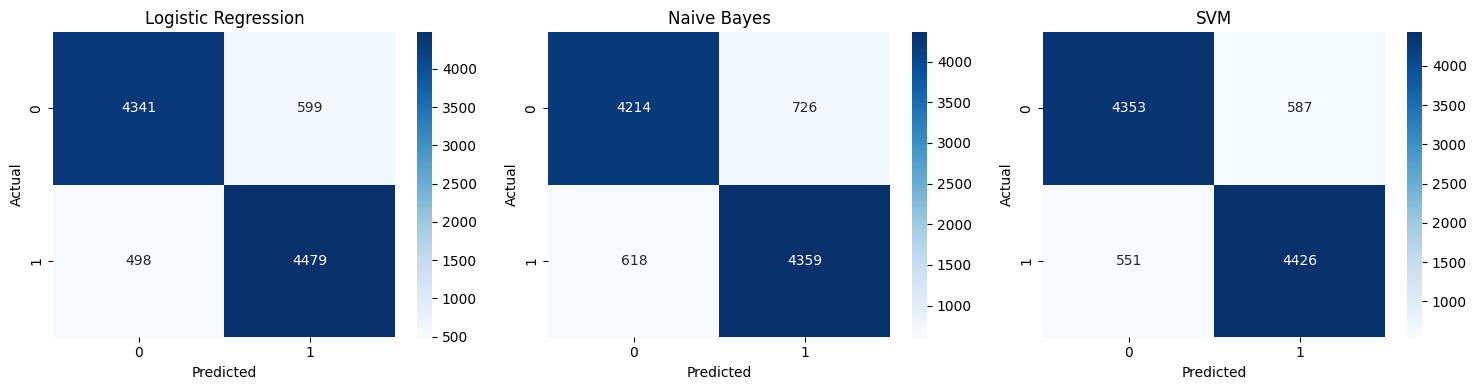

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

predictions = [lr_pred, nb_pred, svm_pred]
names = ["Logistic Regression", "Naive Bayes", "SVM"]

for ax, prediction, name in zip(axes, predictions, names):
    cm = confusion_matrix(y_test, prediction)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

#### Performance comparison graph

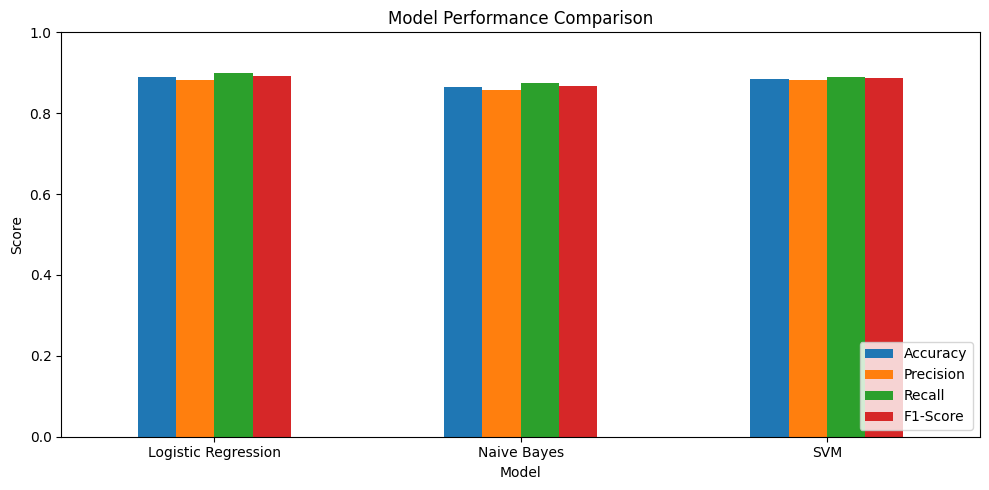

In [27]:
results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

#### Results and Inference

In [28]:
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.889382,0.882040,0.899940,0.890900
1,Naive Bayes,0.864475,0.857227,0.875829,0.866428
2,SVM,0.885248,0.882904,0.889291,0.886086


In [29]:
final_results = results_df.copy()

for col in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    final_results[col] = (final_results[col] * 100).round(2)

final_results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,88.94,88.20,89.99,89.09
1,Naive Bayes,86.45,85.72,87.58,86.64
2,SVM,88.52,88.29,88.93,88.61


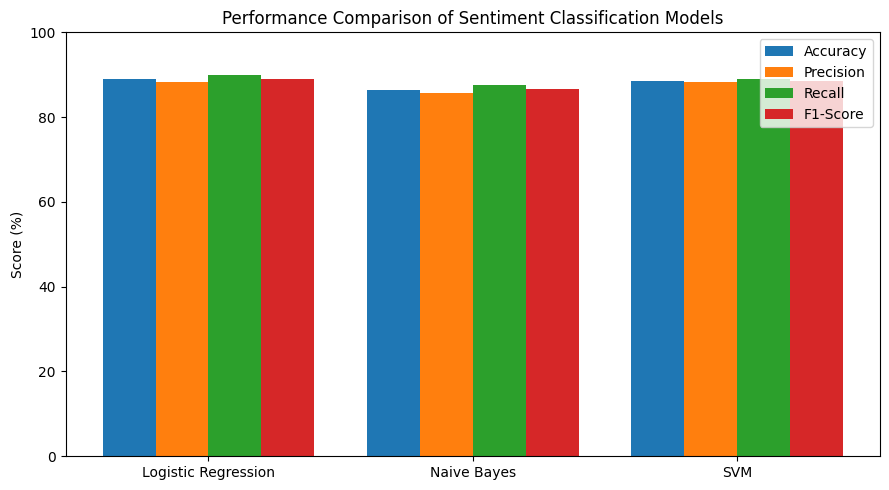

In [30]:
plt.figure(figsize=(9, 5))

x = range(len(final_results))
width = 0.2

plt.bar(
    [i - 1.5 * width for i in x],
    final_results["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    [i - 0.5 * width for i in x],
    final_results["Precision"],
    width,
    label="Precision"
)

plt.bar(
    [i + 0.5 * width for i in x],
    final_results["Recall"],
    width,
    label="Recall"
)

plt.bar(
    [i + 1.5 * width for i in x],
    final_results["F1-Score"],
    width,
    label="F1-Score"
)

plt.xticks(x, final_results["Model"])
plt.ylabel("Score (%)")
plt.title("Performance Comparison of Sentiment Classification Models")
plt.ylim(0, 100)
plt.legend()

plt.tight_layout()
plt.show()

In [31]:
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Highest F1-score:")
print(best_model)

Highest F1-score:
Model        Logistic Regression
Accuracy                0.889382
Precision                0.88204
Recall                   0.89994
F1-Score                  0.8909
Name: 0, dtype: object


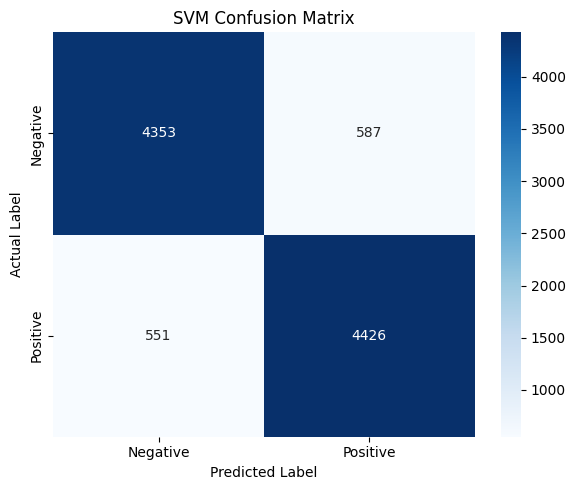

In [32]:
cm = confusion_matrix(y_test, svm_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")

plt.tight_layout()
plt.show()

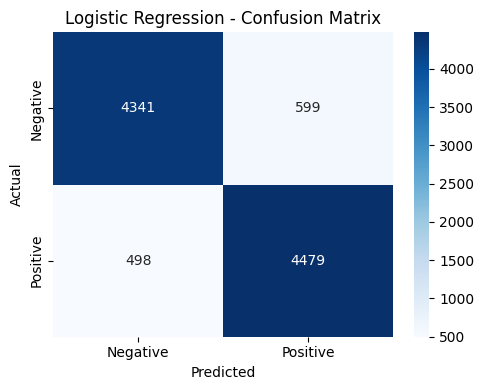

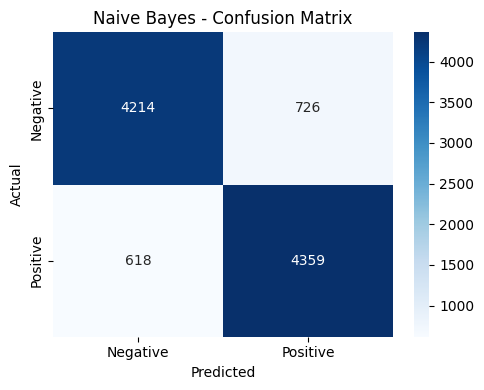

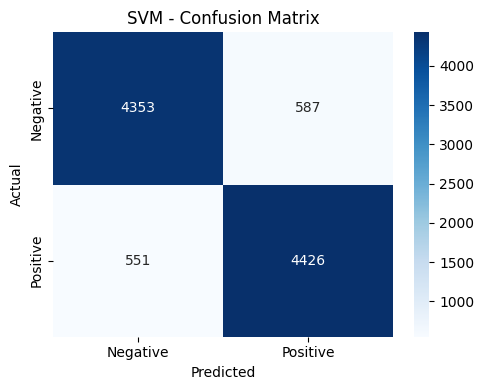

In [33]:
models_pred = {
    "Logistic Regression": lr_pred,
    "Naive Bayes": nb_pred,
    "SVM": svm_pred
}

for name, predictions in models_pred.items():

    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{name} - Confusion Matrix")

    plt.tight_layout()
    plt.show()